# TODO
- quando combino tutti i dataset provo anche senza PCA quella con proteins64
- fare una dimensionality reduction manuale non ha tanto senso perchè le var in input sono embedding senza quindi un significato chiaro
- magari provo anche Supoprt vector machine anche se è dell'altro corso
- potrebbe ever senso sare la mediana invece della media
- potrebbe aver senso droppare proprio i dati borderline (tra 5 e 6) se non sono troppi 
- Capire se fare la media degli embedding raggruppando per inchikey.
- Potrebbe aver senso rimuovere quelle molecole che hanno dev std troppo alta (se > 15 se ne toglierebbero 12 su 714)

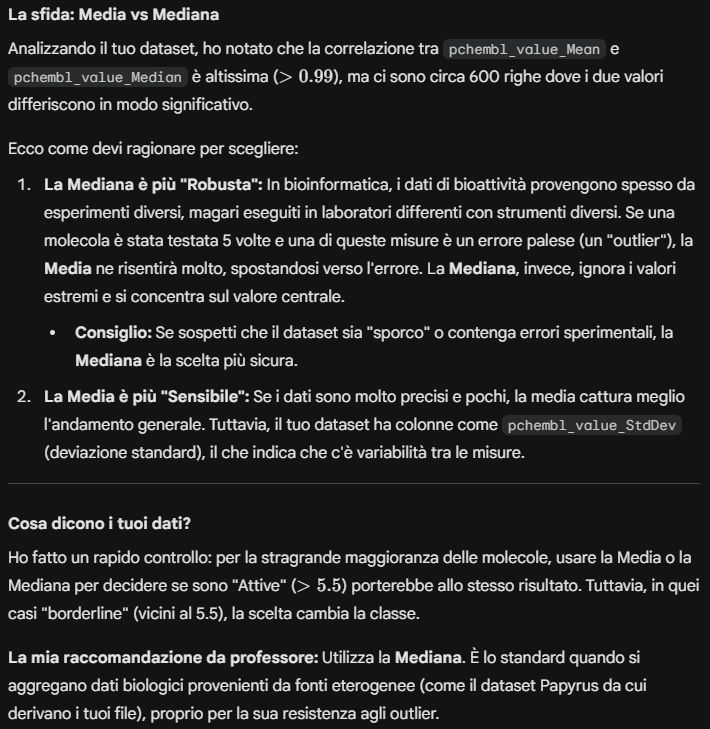

# Predizione della Bioattività di Molecole Prodotte dalle Piante

## Obiettivo
>Sviluppare modelli di machine learning per predire la **bioattività** di molecole prodotte dalle piante.

## Descrizione dataset
Il dataset è composto da 3 componenti:

### 1) "bioactivities" 
>Contiene l'elenco di bioattività tra molecole e proteine target. (source: [Papyrus](https://pmc.ncbi.nlm.nih.gov/articles/PMC9824924/))

- **Identificatori**
  - `Activity_ID` (*"primary key"*): identifica la **bioattività** di una coppia "molecola-proteina"
    - `InChIKey` (*"foreign key"*): identifica una specifica **molecola**
    - `target_id` (*"foreign key"*): identifica una specifica **proteina**

- **Statistiche bioattività**
  - `pchembl_value`: valori di bioattività derivanti da multiple misurazioni
    - 2 interpretazioni euristiche possibili:
      1) la più comune:
         - **Active**$~~~$: $\text{pChembl}  > 5.5$
         - **Inactive**: $\text{pChembl} <= 5.5$
      2) alternativa:
         - **Active**: $\text{pChembl} >= 6.0$
         - **Borderline**: $5.0 <= \text{pChembl} < 6.0$
         - **Inactive**: $\text{pChembl}  < 5.0$
  - `pchembl_value_Mean`: **media** dei valori di bioattività misurati
  - `pchembl_value_StdDev`: **deviazione standard** dei valori di bioattività misurati
  - `pchembl_value_SEM`: **errore standard della media** dei valori di bioattività misurati
  - `pchembl_value_N`: **numero** dei valori di bioattività misurati 
  - `pchembl_value_Median`: **mediana** dei valori di bioattività misurati
  - `pchembl_value_MAD`: **deviazione assoluta dalla mediana** dei valori di bioattività misurati

- **Metadati superfluei**

	
### 2) "mass_spectra_embeddings"
>Contiene gli embedding delle molecole ottenuti con il tool python [Spec2Vec](https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1008724) a partire dagli spettri di massa.

- **Identificatori**
  - `spectrum_id` (*"primary key"*): identifica uno specifico **spettro di una molecola**
    - `inchikey`: identifica una specifica **molecola**

- **Embedding features**
  - \[`0`,...,`499`\]: valori di embedding

- **Metadati superfluei**

### 3) "protein_embeddings"
>Contiene 3 dimensionalità di embedding delle proteine ottenuti con UniRep. (source: [Papyrus](https://pmc.ncbi.nlm.nih.gov/articles/PMC9824924/))
1) File `protein_embeddings_UniRep64.csv`: embedding costituito da 3 componenti da 64 features/colonne, per un totale di 192 features
2) File `protein_embeddings_UniRep256.csv`: embedding costituito da 3 componenti da 256 features/colonne, per un totale di 768 features
3) File `protein_embeddings_UniRep1900.csv`: embedding costituito da 3 componenti da 1900 features/colonne, per un totale di 5700 features

- **Identificatori**
  - `target_id` (*"primary key"*): identifica una specifica **proteina**

- **Embedding features**
  - \[`UniRep64_AH_1`,...,`UniRep64_AH_64`,`UniRep64_FC_1`,...,`UniRep64_FC_64`,`UniRep64_FH_1`,...,`UniRep64_FH_64`\]: valori di embedding per ciascuna delle 3 componenti
  - \[`UniRep256_AH_1`,...,`UniRep256_AH_256`,`UniRep256_FC_256`,...
  - \[`UniRep1900_AH_1`,...,`UniRep1900_AH_1900`,`UniRep1900_FC_1900`,...


## Struttura del Notebook
1. Ipotesi e deduzioni
2. Configurazione ambiente ed import librerie
3. Caricamento dei dataset
4. Preprocessing
5. Validazione modelli
6. Salvataggio modelli
7. Conclusioni

---

# 1) Ipotesi e deduzioni
Dato che i dataset di molecole e proteine contengono rispettivamente
- 5798 spettri di massa per 714 molecole distinte (circa 8 per molecola) e
- 1142 proteine distinte

avere 10092 "bioattività" per 714 molecole e 1142 proteine significa che
- ciascuna **proteina** è stata testata con circa 9 **molecole** ($10092/1142=8.83$) e
- ciascuna **molecola** è stata testata con circa 14 **proteine** ($10092/1142=14.13$)

Da ciò si evince che
- si è cercato studiare il comportamente di "poche" molecole ma "a fondo"
- in fase di join dei dataset, sarà necessario decidere se
  -  **aggregare** gli spettri di massa 
  -  **non aggregare** gli spettri di massa nel caso si renda necessaria la Data Augmentation
___
Visto che l'obiettivo è costruire un classificatore che possa aiutare a identificare le molecole che hanno un "qualsiasi tipo di effetto" (bioattività) quando combinate con una proteina e che quindi vale la pena analizzare, la priorità è **evitare falsi negativi** perché i falsi positivi causeranno solo una piccola perdita di tempo in laboratorio.

Per questo motivo si è scelto di affrontare tale problema tramite **classificazione** piuttosto che **regressione** in modo da poter massimizzare il valore di ***recall*** invece di minimizzare l'errore sul valore di bioattività.

Inoltre, sono stati indicati 2 diversi criteri per classificare le bioattività e nessuna delle due dà origine a classi bilanciate infatti
- con soglia $5.5$:
  - 3651 `active`
  - 6441 `inactive`
- con soglie $5.0$ e $6.0$:
  - 2329 `active`
  - 6044 `borderline`
  - 1719 `inactive`

Per entrambi questi motivi è stato deciso di scegliere come unica soglia quella che **bilancia meglio le classi** cercando nell'intervallo compreso tra $5.0$ e $5.5$ inclusi: in questo modo c'è la possibilità di **bilanciare le classi** e al contempo di **sfavorire i falsi negativi** considerando come `active` anche alcuni valori `borderline`. 

Questo ha portato inoltre a scegliere la classificazione **binaria** rispetto a quella ternaria.
___
Data la dimensionalità dei dataset, per la classificazione si è scelto di effettuare una feature reduction tramite
- **PCA** (tecnica adoperata dal modello di riferimento) e
- **LDA** (più adatto in ambito classificazione)

e di utilizzare i modelli
- **Random forest** (perfetto per la classificazione) e
- **XGBoost** (tecnica adoperata dal modello di riferimento)

In particolare verranno confrontate le combinazioni
- **PCA + XGBoost** (modello di riferimento)
- **LDA + XGBoost**
- **LDA + Random forest**
___
Data la presenza di **3 dimensionalità** di embedding per le proteine, i modelli verranno testati **con ciascuno di essi preso singolarmente** e anche con **l'embedding da 64 feature senza dimensionality reduction**.
___

# 2) Configurazione ambiente ed import librerie

In [43]:
# Data manipulation
import pandas as pd
import numpy as np
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

# Models
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
import xgboost as xgb

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score
)

# Deep Learning (PyTorch)
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Utilities
from tqdm import tqdm
import time
from collections import Counter


# Configurazione per rilevamento GPU (Colab/HPC)
#import warnings
#warnings.filterwarnings('ignore')

# Verifica disponibilità GPU
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA disponibile: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Numero di GPU: {torch.cuda.device_count()}")
    DEVICE = torch.device("cuda")
else:
    print("Utilizzo CPU")
    DEVICE = torch.device("cpu")

# Set random seeds for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

# Plot style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

PyTorch version: 2.7.0+cpu
CUDA disponibile: False
Utilizzo CPU


# 3) Caricamento ed esplorazione del dataset

In [44]:
# Percorso base del dataset (modificare se necessario per Colab)
# Per Google Colab: montare prima il drive e modificare il path
# from google.colab import drive
# drive.mount('/content/drive')
# BASE_PATH = Path('/content/drive/MyDrive/dataset_bioactivities')

# Per esecuzione locale
BASE_PATH = Path('dataset_bioactivities')

# Caricamento bioactivities
print("📊 Caricamento bioactivities...")
df_bioactivities = pd.read_csv(BASE_PATH / 'bioactivities' / 'dataset_bioactivities_negative.csv')

# Caricamento molecule embeddings
print("📊 Caricamento mass_spectra_embeddings...")
df_molecules = pd.read_csv(BASE_PATH / 'mass_spectra_embeddings' / 'ALL_GNPS_negative_ionization_DATASET.csv')

# Caricamento protein embeddings (3 dimensionalità)
print("📊 Caricamento protein_embeddings...")
df_proteins_64 = pd.read_csv(BASE_PATH / 'protein_embeddings' / 'protein_embeddings_UniRep64.csv')
df_proteins_256 = pd.read_csv(BASE_PATH / 'protein_embeddings' / 'protein_embeddings_UniRep256.csv')
df_proteins_1900 = pd.read_csv(BASE_PATH / 'protein_embeddings' / 'protein_embeddings_UniRep1900.csv')

print(f"\n✅ Dataset caricati con successo!")
print(f"   - Bioactivities: {df_bioactivities.shape}")
print(f"   - Molecules: {df_molecules.shape}")
print(f"   - Proteins (UniRep64): {df_proteins_64.shape}")
print(f"   - Proteins (UniRep256): {df_proteins_256.shape}")
print(f"   - Proteins (UniRep1900): {df_proteins_1900.shape}")

📊 Caricamento bioactivities...
📊 Caricamento mass_spectra_embeddings...
📊 Caricamento protein_embeddings...

✅ Dataset caricati con successo!
   - Bioactivities: (10092, 36)
   - Molecules: (5798, 507)
   - Proteins (UniRep64): (1142, 193)
   - Proteins (UniRep256): (1142, 769)
   - Proteins (UniRep1900): (1142, 5701)


In [45]:
df_bioactivities

,Activity_ID,Quality,source,CID,SMILES,connectivity,InChIKey,InChI,InChI_AuxInfo,target_id,...,pchembl_value_N,pchembl_value_Median,pchembl_value_MAD,HGNC_symbol,UniProtID,Status,Organism,Classification,Length,Sequence
0,AAKJLRGGTJKAMG_on_P00533_WT,High,ChEMBL30,CHEMBL553;2050;2050;2050;CHEMBL553;CHEMBL553;2...,C#Cc1cc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)ccc1,AAKJLRGGTJKAMG,AAKJLRGGTJKAMG-UHFFFAOYSA-N,InChI=1S/C22H23N3O4/c1-4-16-6-5-7-17(12-16)25-...,"""AuxInfo=1/1/N:1,24,18,2,28,29,27,22,16,21,15,...",P00533_WT,...,514,7.550,0.86,EGFR,EGFR_HUMAN,reviewed,Homo sapiens (Human),Enzyme->Kinase->Protein Kinase->TK protein kin...,1210,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...
1,ACPOUJIDANTYHO_on_P00533_WT,High,Sharma2016,1800164;Merget2017.compound.1660;Christmann201...,O=C1c2c(cccc2)-c2c3c1cccc3n[nH]2,ACPOUJIDANTYHO,ACPOUJIDANTYHO-UHFFFAOYSA-N,InChI=1S/C14H8N2O/c17-14-9-5-2-1-4-8(9)13-12-1...,"""AuxInfo=1/1/N:6,7,13,5,8,12,14,4,3,11,15,10,9...",P00533_WT,...,14,5.700,0.00,EGFR,EGFR_HUMAN,reviewed,Homo sapiens (Human),Enzyme->Kinase->Protein Kinase->TK protein kin...,1210,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...
2,AFSDNFLWKVMVRB_on_P00533_WT,High,ExCAPE-DB,5281855;Merget2017.compound.1659;CHEMBL6246;52...,O=c1oc2c3c(cc(O)c2O)c(=O)oc2c(O)c(O)cc1c23,AFSDNFLWKVMVRB,AFSDNFLWKVMVRB-UHFFFAOYSA-N,InChI=1S/C14H6O8/c15-5-1-3-7-8-4(14(20)22-11(7...,"""AuxInfo=1/0/N:7,20,6,21,8,18,5,22,10,16,4,15,...",P00533_WT,...,12,6.161,0.00,EGFR,EGFR_HUMAN,reviewed,Homo sapiens (Human),Enzyme->Kinase->Protein Kinase->TK protein kin...,1210,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...
3,AILRADAXUVEEIR_on_P00533_WT,High,ChEMBL30,CHEMBL3545311,COc1cc(N2CCC(N3CCN(C)CC3)CC2)ccc1Nc1ncc(Cl)c(N...,AILRADAXUVEEIR,AILRADAXUVEEIR-UHFFFAOYSA-N,InChI=1S/C29H39ClN7O2P/c1-35-15-17-37(18-16-35...,"""AuxInfo=1/1/N:14,1,37,38,32,33,31,34,19,20,8,...",P00533_WT,...,34,8.600,0.40,EGFR,EGFR_HUMAN,reviewed,Homo sapiens (Human),Enzyme->Kinase->Protein Kinase->TK protein kin...,1210,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...
4,ATEFPOUAMCWAQS_on_P00533_WT,High,Sharma2016,14348,O=c1ccc2c(o1)c(O)c(O)cc2,ATEFPOUAMCWAQS,ATEFPOUAMCWAQS-UHFFFAOYSA-N,InChI=1S/C9H6O4/c10-6-3-1-5-2-4-7(11)13-9(5)8(...,"""AuxInfo=1/0/N:13,4,12,3,5,10,2,8,6,11,1,9,7/r...",P00533_WT,...,8,5.115,0.00,EGFR,EGFR_HUMAN,reviewed,Homo sapiens (Human),Enzyme->Kinase->Protein Kinase->TK protein kin...,1210,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10087,XNYZHCFCZNMTFY_on_P19801_WT,High,ChEMBL30,CHEMBL35241,N=C(N)c1ccc(N=NNc2ccc(C(=N)N)cc2)cc1,XNYZHCFCZNMTFY,XNYZHCFCZNMTFY-UHFFFAOYSA-N,InChI=1S/C14H15N7/c15-13(16)9-1-5-11(6-2-9)19-...,"""AuxInfo=1/1/N:5,21,13,18,6,20,12,19,4,14,7,11...",P19801_WT,...,2,7.890,0.00,NaN,AOC1_HUMAN,reviewed,Homo sapiens (Human),Enzyme,751,MPALGWAVAAILMLQTAMAEPSPGTLPRKAGVFSDLSNQELKAVHS...
10088,XNYZHCFCZNMTFY_on_P21673_WT,High,ChEMBL30,CHEMBL35241,N=C(N)c1ccc(N=NNc2ccc(C(=N)N)cc2)cc1,XNYZHCFCZNMTFY,XNYZHCFCZNMTFY-UHFFFAOYSA-N,InChI=1S/C14H15N7/c15-13(16)9-1-5-11(6-2-9)19-...,"""AuxInfo=1/1/N:5,21,13,18,6,20,12,19,4,14,7,11...",P21673_WT,...,2,5.620,0.00,NaN,SAT1_HUMAN,reviewed,Homo sapiens (Human),Enzyme->Transferase,171,MAKFVIRPATAADCSDILRLIKELAKYEYMEEQVILTEKDLLEDGF...
10089,XUZMWHLSFXCVMG_on_Q01844_WT,High,Klaeger2017,Klaeger2017.compound.37,CCS(=O)(=O)N1CC(CC#N)(n2cc(-c3ncnc4c3cc[nH]4)c...,XUZMWHLSFXCVMG,XUZMWHLSFXCVMG-UHFFFAOYSA-N,"InChI=1S/C16H17N7O2S/c1-2-26(24,25)22-9-16(10-...","""AuxInfo=1/1/N:1,2,21,9,10,22,24,13,7,26,17,14...",Q01844_WT,...,4,7.745,0.00,EWSR1,EWS_HUMAN,reviewed,Homo sapiens (Human),Unclassified protein,656,MASTDYSTYSQAAAQQGYSAYTAQPTQGYAQTTQAYGQQSYGTYGQ...
10090,XUZMWHLSFXCVMG_on_Q9NY27_WT,High,Klaeger2017,Klaeger2017.compound.37,CCS(=O)(=O)N1CC(CC#N)(n2cc(-c3ncnc4c3cc[nH]4)c...,XUZMWHLSFXCVMG,XUZMWHLSFXCVMG-UHFFFAOYSA-N,"InChI=1S/C16H17N7O2S/c1-2-26(24,25)22-9-16(10-...","""AuxInfo=1/1/N:1,2,21,9,10,22,24,13,7,26,17,14...",Q9NY27_WT,...,4,7.25

In [46]:
df_molecules

,inchikey,backbone_inchikey,spectrum_id,smiles,inchi,instrument,ms_level,0,1,2,...,490,491,492,493,494,495,496,497,498,499
0,REFJWTPEDVJJIY-UHFFFAOYSA-N,REFJWTPEDVJJIY,CCMSLIB00000077171,C1=CC(=C(C=C1C2=C(C(=O)C3=C(C=C(C=C3O2)O)O)O)O)O,InChI=1S/C15H10O7/c16-7-4-10(19)12-11(5-7)22-1...,Ion Trap,2,9.607846,2.802023,8.878453,...,-2.267261,7.410372,-0.767007,-14.296808,12.043738,-0.535357,3.684344,-2.610004,4.438908,22.484255
1,DANYIYRPLHHOCZ-UHFFFAOYSA-N,DANYIYRPLHHOCZ,CCMSLIB00000077212,O=C1C2=C(C=C(C=C2OC(C3=CC=C(C=C3)OC)=C1)O)O,InChI=1S/C16H12O5/c1-20-11-4-2-9(3-5-11)14-8-1...,Ion Trap,2,-3.743248,8.963512,-13.119514,...,0.850199,1.896127,-1.428571,2.617292,0.967600,-7.100490,4.839757,2.050162,-2.505632,8.013733
2,REFJWTPEDVJJIY-UHFFFAOYSA-N,REFJWTPEDVJJIY,CCMSLIB00000077221,O=C1C2=C(C=C(C=C2OC(C3=CC(O)=C(C=C3)O)=C1O)O)O,InChI=1S/C15H10O7/c16-7-4-10(19)12-11(5-7)22-1...,Ion Trap,2,15.296115,5.382534,11.653003,...,-3.729640,7.611222,-0.269078,-31.249656,19.250404,-0.056575,8.586094,-11.137173,8.047441,27.927703
3,WEPBGSIAWZTEJR-UHFFFAOYSA-N,WEPBGSIAWZTEJR,CCMSLIB00000077223,O=C1C2=C(O)C=C(O)C=C2OC(C3=CC(O)=C(O)C=C3)=C1OC,InChI=1S/C16H12O7/c1-22-16-14(21)13-11(20)5-8(...,qTof,2,2.587487,-9.726512,-5.610098,...,13.326739,-1.829110,11.330718,2.624641,12.474549,-16.206268,-9.119176,-3.557700,-22.368920,-9.876165
4,FXNFHKRTJBSTCS-UHFFFAOYSA-N,FXNFHKRTJBSTCS,CCMSLIB00000077226,O=C1C2=C(O)C(O)=C(O)C=C2OC(C3=CC=CC=C3)=C1,InChI=1S/C15H10O5/c16-9-6-11(8-4-2-1-3-5-8)20-...,qTof,2,-11.276055,3.991606,-6.219286,...,20.143283,-12.907214,20.991170,6.716496,-12.201179,-23.204450,-18.559520,2.654958,-32.627998,18.730554
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5793,DANYIYRPLHHOCZ-UHFFFAOYSA-N,DANYIYRPLHHOCZ,CCMSLIB00004683981,COc1ccc(cc1)c2cc(=O)c3c(cc(cc3o2)O)O,InChI=1S/C16H12O5/c1-20-11-4-2-9(3-5-11)14-8-1...,impact HD,2,14.329692,13.079878,5.756769,...,6.417844,-2.512271,6.751256,1.389466,-3.304776,-1.515792,-13.919465,-6.961419,-9.796392,0.059967
5794,QIQXTHQIDYTFRH-UHFFFAOYSA-N,QIQXTHQIDYTFRH,CCMSLIB00004684075,CCCCCCCCCCCCCCCCCC(=O)O,InChI=1S/C18H36O2/c1-2-3-4-5-6-7-8-9-10-11-12-...,impact HD,2,6.989496,4.729643,-15.990228,...,3.185644,7.655814,14.964863,1.702161,-6.624478,-6.515879,-3.857400,13.081180,6.470927,-0.355202
5795,LKOJGSWUMISDOF-UHFFFAOYSA-N,LKOJGSWUMISDOF,CCMSLIB00004684099,COc1c(cc2c(c1O)c(=O)cc(o2)c3ccccc3)O,InChI=1S/C16H12O5/c1-20-16-11(18)8-13-14(15(16...,impact HD,2,1.996257,-3.806559,-7.551622,...,7.084883,-1.750906,8.428929,-3.933588,12.208838,-5.254452,-10.687805,-2.370923,-13.982405,-10.424351
5796,LKOJGSWUMISDOF-UHFFFAOYSA-N,LKOJGSWUMISDOF,CCMSLIB00004684100,COc1c(cc2c(c1O)c(=O)cc(o2)c3ccccc3)O,InChI=1S/C16H12O5/c1-20-16-11(18)8-13-14(15(16...,impact HD,2,11.374275,-5.898643,-5.371347,...,-7.863005,-6.672494,13.551168,14.498432,18.518915,-12.364852,-37.476517,0.812095,-26.493843,-13.222843


In [47]:
df_proteins_64

,target_id,UniRep64_AH_1,UniRep64_AH_2,UniRep64_AH_3,UniRep64_AH_4,UniRep64_AH_5,UniRep64_AH_6,UniRep64_AH_7,UniRep64_AH_8,UniRep64_AH_9,...,UniRep64_FH_55,UniRep64_FH_56,UniRep64_FH_57,UniRep64_FH_58,UniRep64_FH_59,UniRep64_FH_60,UniRep64_FH_61,UniRep64_FH_62,UniRep64_FH_63,UniRep64_FH_64
0,P08908_WT,-0.03340,0.12100,0.07972,-0.96452,-0.00455,-0.21062,0.11217,0.16754,0.45682,...,0.17631,0.02618,-0.01992,0.03488,-0.06542,0.12924,0.00009,-0.01309,0.36438,-0.01597
1,P78536_WT,-0.05195,0.11108,-0.13302,-0.95709,-0.02030,-0.24622,0.06457,0.17375,0.34255,...,0.19816,0.04163,0.10696,-0.11379,0.00808,0.21009,-0.14236,-0.06104,0.18948,0.04030
2,P00533_WT,-0.06079,0.10365,-0.13963,-0.95773,-0.02972,-0.26442,0.06775,0.17635,0.32052,...,0.15329,0.07576,0.06990,-0.05594,0.04035,0.11908,-0.09652,-0.03919,0.31088,-0.08087
3,P04626_WT,0.00469,0.11845,-0.12057,-0.96886,-0.04806,-0.28627,0.05622,0.17412,0.29410,...,0.20267,0.10853,0.11290,-0.12663,0.02623,0.27940,-0.22777,-0.07553,0.29795,-0.01488
4,P06239_WT,-0.01452,0.11377,-0.14992,-0.96105,-0.04525,-0.21679,0.07543,0.19003,0.32114,...,0.14567,0.01499,-0.04908,-0.02009,-0.00895,0.16969,-0.28225,-0.07568,0.25715,0.01800
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1137,P10721_L576P,-0.04066,0.12321,-0.13649,-0.93982,-0.02499,-0.25130,0.10393,0.18092,0.36781,...,0.11017,0.03093,0.04937,-0.13143,0.00237,0.15812,-0.09143,-0.07080,0.27359,-0.02004
1138,P36888_R834Q,-0.03231,0.10215,-0.12013,-0.95230,-0.03304,-0.25532,0.08182,0.13921,0.37015,...,0.13469,0.03314,0.02721,-0.03719,-0.00083,0.13635,-0.09172,-0.05646,0.30378,0.05328
1139,P10721_A829P,-0.04047,0.12368,-0.13714,-0.93952,-0.02506,-0.25028,0.10417,0.18232,0.36993,...,0.11003,0.03142,0.05007,-0.13074,0.00168,0.16064,-0.09213,-0.07055,0.27338,-0.01918
1140,P08581_Y1235D,-0.02935,0.09748,-0.13171,-0.94943,-0.02367,-0.27288,0.07457,0.18881,0.35783,...,0.13613,0.02566,0.09254,-0.03924,-0.02545,0.14029,-0.08185,-0.06756,0.30430,0.00449


# 4) Preprocessing

## Data cleaning
La parte di Data Cleaning è già stata effettuata infatti:
- non ci sono dati mancanti (a parte nei metadati superflui)
- nel dataset delle bioattività 
  - il dominio della feature `Quality` contiene solo la qualità "**High**"
  - il dominio della feature `Status` contiene solo il valore **reviewed**
    - ogni misurazione è stata controllata manualmente
- il dominio della feature `ms_level` del dataset delle molecole contiene solo il valore $2$
  - gli embedding sono ricchi di informazione perché comprendono le singole componenti della molecola invece che solo la molecola intera (`ms_level` $= 1$)

## Feature selection

>Rimozione **metadati superfluei** e **statistiche di bioattività** superflue.

In [48]:
# come statistica di bioattività si prende come riferimento pchembl_value_Mean
df_bioactivities.drop(columns=[
    'Quality', 'source', 'CID', 'SMILES', 'connectivity', 'InChI', 'InChI_AuxInfo', 'accession',
    'Protein_Type', 'AID', 'doc_id', 'Year', 'all_doc_ids', 'all_years', 'type_IC50', 'type_EC50',
    'type_KD', 'type_Ki', 'relation', 'HGNC_symbol', 'UniProtID', 'Status', 'Organism', 'Classification',
    'Length', 'Sequence',
    'pchembl_value', 'pchembl_value_StdDev', 'pchembl_value_SEM',
    'pchembl_value_N', 'pchembl_value_Median', 'pchembl_value_MAD'    
], inplace=True)

df_molecules.drop(columns=[
    'backbone_inchikey', 'smiles', 'inchi', 'instrument', 'ms_level'
], inplace=True)

## Data preparation

>Si cerca la soglia che meglio bilancia le classi.

In [49]:
# Si ricerca nel range "safe" delle soglie (5.00-5.50)
pchembl_values = np.array(df_bioactivities['pchembl_value_Mean'].values)
thresholds = np.arange(5.00, 5.51, 0.01)

# Si contano gli attivi per ogni soglia (e gli inattivi per differenza)
active_counts = np.array([(pchembl_values >= t).sum() for t in thresholds])
inactive_counts = len(pchembl_values) - active_counts

# Si individua la soglia che minimizza la differenza tra le classi
best_idx = np.argmin(np.abs(active_counts - inactive_counts))
best_balancing_threshold = thresholds[best_idx]

print(f"Soglia ottimale: {best_balancing_threshold:.2f}")
print(f"active: {active_counts[best_idx]} | inactive: {inactive_counts[best_idx]}")

Soglia ottimale: 5.16
active: 5058 | inactive: 5034


>Viene aggiunta la colonna indicante la classe per ogni bioattività secondo la soglia trovata.

In [50]:
df_bioactivities['bioactivity_class'] = np.where(
    df_bioactivities['pchembl_value_Mean'] >= best_balancing_threshold,
    'active',
    'inactive'
)

>Si mediano gli spettri di massa delle molecole raggruppando per `inchikey`.

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271,272,273,274,275,276,277,278,279,280,281,282,283,284,285,286,287,288,289,290,291,292,293,294,295,296,297,298,299,300,301,302,303,304,305,306,307,308,309,310,311,312,313,314,315,316,317,318,319,320,321,322,323,324,325,326,327,328,329,330,331,332,333,334,335,336,337,338,339,340,341,342,343,344,345,346,347,348,349,350,351,352,353,354,355,356,357,358,359,360,361,362,363,364,365,366,367,368,369,370,371,372,373,374,375,376,377,378,379,380,381,382,383,384,385,386,387,388,389,390,391,392,393,394,395,396,397,398,399,400,401,402,403,404,405,406,407,408,409,410,411,412,413,414,415,416,417,418,419,420,421,422,423,424,425,426,427,428,429,430,431,432,433,434,435,436,437,438,439,440,441,442,443,444,445,446,447,448,449,450,451,452,453,454,455,456,457,458,459,460,461,462,463,464,465,466,467,468,469,470,471,472,473,474,475,476,477,478,479,480,481,482,483,484,485,486,487,488,489,490,491,492,493,494,495,496,497,498,499
inchikey,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
AAKJLRGGTJKAMG-UHFFFAOYSA-N,6.245247,6.519279,5.934610,4.540856,6.620523,2.489483,4.381078,3.615169,3.109058,3.660529,4.451940,5.745883,7.559962,4.072365,6.476132,2.762566,5.559808,5.298071,4.471965,5.433236,2.821211,5.248882,8.598880,3.000066,3.317040,4.544859,3.507447,7.236271,4.791240,5.801438,1.887501,5.301551,5.565051,2.983124,4.779495,7.720690,6.894780,3.291625,4.337847,5.250978,8.326598,5.023936,4.167488,3.673592,3.883446,4.454034,7.420617,5.938713,2.362372,4.903486,5.173638,7.085118,3.828226,5.884381,3.647579,1.985799,7.400339,3.819605,8.724922,4.069016,2.324248,7.068235,5.583627,3.433223,6.720887,5.593629,13.330762,2.576635,3.874636,2.828036,1.964641,4.809433,3.541902,4.285640,11.853618,2.445744,3.543682,5.071759,6.108277,2.740030,3.747463,3.332383,4.184660,3.375543,1.473818,3.566706,4.922288,3.834802,2.777451,3.641698,2.190015,5.344883,3.627319,3.441393,7.160561,3.780149,5.795002,5.117981,3.116871,3.133475,9.119175,3.137550,2.901723,4.113330,4.926637,2.375998,8.510843,4.103376,4.599676,2.929272,4.399861,2.827019,4.099470,3.751990,7.332543,8.570676,4.515918,4.370002,5.528323,4.463937,8.949697,4.270883,5.183964,2.365579,2.440770,5.293023,3.005298,4.836753,4.409059,4.871914,8.967565,3.337286,4.238609,4.372762,4.126597,2.543023,2.406299,6.835798,3.549907,5.096826,3.309720,3.044159,5.965909,6.098861,5.383633,9.220648,3.889325,6.023070,5.211509,2.271914,8.556606,7.892395,6.524756,4.193706,6.176950,4.839880,2.771266,3.548271,3.720601,7.147171,4.075418,2.660119,1.847140,4.171321,4.480091,6.582717,4.345963,2.363816,6.724311,4.670910,3.863274,4.679483,2.626475,4.646948,4.39

>Si effettuano 3 merge tra i data set considerando per ciascuno una sola dimensionalità di embedding di proteine e creando una copia del dataset con l'embedding da 64 feature che non sarà soggetto a dimensionality reduction.

inchikey
AAKJLRGGTJKAMG-UHFFFAOYSA-N     4.871758
ACPOUJIDANTYHO-UHFFFAOYSA-N          NaN
ADFWQBGTDJIESE-UHFFFAOYSA-N          NaN
ADIMAYPTOBDMTL-UHFFFAOYSA-N    14.164158
AFDXODALSZRGIH-UHFFFAOYSA-N          NaN
                                 ...    
ZZAJQOPSWWVMBI-UHFFFAOYSA-N     6.256800
ZZIALNLLNHEQPJ-UHFFFAOYSA-N     8.430542
ZZORFUFYDOWNEF-UHFFFAOYSA-N     6.351680
ZZUFCTLCJUWOSV-UHFFFAOYSA-N     4.541478
ZZVUWRFHKOJYTH-UHFFFAOYSA-N     3.771936
Length: 714, dtype: float64

>Si effettua la riduzione della dimensionalità tramite **PCA** o **LDA** per i 3 dataset.

>Si separano **Train Set** e **Test Set** per ciascuno dei 4 dataset con l'accorgimento di mantenere in entrambi la stessa distribuzione di `active` e `inactive` tramite il parametro `stratify` settato a **true**.

>Si **standardizza** ciascun dataset.

# 5) Validazioni modelli

>Si definiscono i modelli **XGBoost** e **Random forest**.

>Si **addestrano** i modelli.

>Si **validano** le prestazioni confrontando le combinazioni di dataset, tecnica di riduzione di dimensionalità e modello sui seguenti indici:
- *Precision*
- *Recall*
- *Accuracy*
- *F1-score*  

# 6) Salvataggio modelli

# 7) Conclusioni

# -------------------------------------

---

## Appendice A: Istruzioni per l'Esecuzione

### Esecuzione su Google Colab

```python
# 1. Monta Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Copia il dataset
!cp -r "/content/drive/MyDrive/dataset_bioactivities" "/content/"

# 3. Installa dipendenze (se necessario)
!pip install xgboost torch scikit-learn pandas matplotlib seaborn

# 4. Modifica BASE_PATH nel notebook
BASE_PATH = Path('/content/dataset_bioactivities/dataset_bioactivities')
```

### Esecuzione su HPC con GPU

```bash
# 1. Richiedi un nodo con GPU
#SBATCH --gres=gpu:1
#SBATCH --partition=gpu

# 2. Carica i moduli necessari
module load python/3.10
module load cuda/11.8

# 3. Attiva l'ambiente virtuale
source venv/bin/activate

# 4. Esegui il notebook
jupyter nbconvert --execute --to notebook main.ipynb
```

### Requisiti
- Python >= 3.8
- PyTorch >= 2.0 (con CUDA per GPU)
- scikit-learn >= 1.0
- xgboost >= 1.5
- pandas >= 1.3
- matplotlib >= 3.5
- seaborn >= 0.11